In [3]:
import pandas as pd

df = pd.read_csv("/Users/prashastitripathi/Downloads/people-analytics 2/data/raw/2024/FEVS_2024_PRDF_rv20250625.csv")

print(df.head())

       RandomID    POSTWT agency level1   Q1   Q2   Q3   Q4   Q5   Q6  ...  \
0  112970976817  1.597695     XX   XXZZ  3.0  4.0  4.0  4.0  1.0  NaN  ...   
1  194868625278  1.828360     XX   XXZZ  3.0  3.0  4.0  4.0  4.0  4.0  ...   
2  152966380283  1.867398     XX   XXZZ  2.0  1.0  3.0  3.0  3.0  2.0  ...   
3  193041162980  2.077359     XX   XXZZ  4.0  5.0  5.0  5.0  2.0  5.0  ...   
4  146655962451  1.494947     XX   XXZZ  4.0  4.0  4.0  4.0  4.0  4.0  ...   

   Q91 DRNO  DHISP  DDIS  DAGEGRP  DSUPER  DFEDTEN  DSEX  DMIL  DLEAVING  
0  2.0    B      B     B        B       B        B     A     B         D  
1  3.0    B      B     B        B       B        B     A     A         A  
2  3.0    B      B     B        B       A        A     A     A         A  
3  2.0    B      B     B        B       A        A     A     A         A  
4  3.0    B      B     A        B       B        C     A     A         A  

[5 rows x 96 columns]


In [4]:
df.shape

(87321, 96)

In [5]:
df[["Q86", "Q87", "Q88", "Q89", "Q90"]].isna().sum()

Q86    3861
Q87    4069
Q88    3705
Q89    3897
Q90    3672
dtype: int64

In [15]:
data = df.dropna(subset=["Q86", "Q87", "Q88", "Q89", "Q90"]).copy()

print(data.shape[0])

82012


In [16]:
data["engagement_score"] = data[["Q86", "Q87", "Q88", "Q89", "Q90"]].mean(axis=1)

print(data["engagement_score"].head())

0    4.8
1    3.4
2    2.8
3    5.0
4    4.4
Name: engagement_score, dtype: float64


In [17]:
data["engagement_score"].describe()

count    82012.000000
mean         3.965073
std          0.814915
min          1.000000
25%          3.600000
50%          4.000000
75%          4.600000
max          5.000000
Name: engagement_score, dtype: float64

In [18]:
data["Q1"] = pd.to_numeric(data["Q1"], errors="coerce")
data["Q5"] = pd.to_numeric(data["Q5"], errors="coerce")
data["Q50"] = pd.to_numeric(data["Q50"], errors="coerce")
data["Q57"] = pd.to_numeric(data["Q57"], errors="coerce")

print(data[["Q1", "Q5", "Q50", "Q57"]].head())

    Q1   Q5  Q50  Q57
0  3.0  1.0  3.0  3.0
1  3.0  4.0  4.0  2.0
2  2.0  3.0  4.0  1.0
3  4.0  2.0  5.0  4.0
4  4.0  4.0  5.0  3.0


In [19]:
analysis_data = data.dropna(subset=["Q1", "Q5", "Q50", "Q57"]).copy()

print(analysis_data.shape[0])

78685


In [20]:
analysis_data[["Q1", "Q5", "Q50", "Q57"]].describe()

,Q1,Q5,Q50,Q57
count,78685.000000,78685.000000,78685.000000,78685.000000
mean,3.945415,3.532656,4.302180,3.391815
std,1.001413,1.189022,0.970539,1.213195
min,1.000000,1.000000,1.000000,1.000000
25%,4.000000,3.000000,4.000000,3.000000
50%,4.000000,4.000000,5.000000,4.000000
75%,5.000000,4.000000,5.000000,4.000000
max,5.000000,5.000000,5.000000,5.000000


In [21]:
analysis_data[["engagement_score", "Q1", "Q5", "Q50", "Q57"]].corr()

,engagement_score,Q1,Q5,Q50,Q57
engagement_score,1.000000,0.577027,0.362752,0.457333,0.573349
Q1,0.577027,1.000000,0.405498,0.517836,0.517228
Q5,0.362752,0.405498,1.000000,0.322157,0.393904
Q50,0.457333,0.517836,0.322157,1.000000,0.396278
Q57,0.573349,0.517228,0.393904,0.396278,1.000000


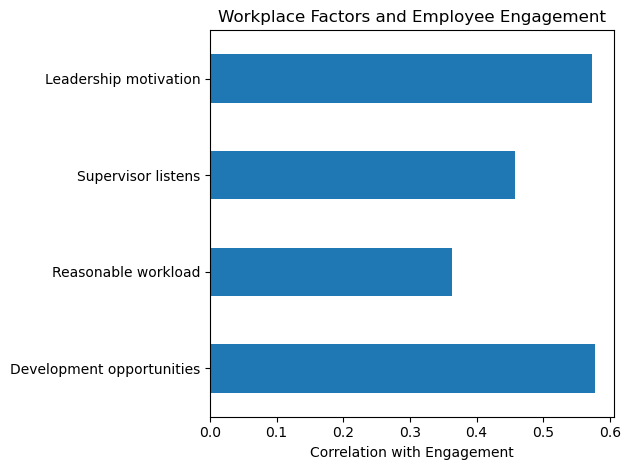

In [25]:
import matplotlib.pyplot as plt

correlations = analysis_data[["engagement_score", "Q1", "Q5", "Q50", "Q57"]].corr()

values = correlations.loc["engagement_score", ["Q1", "Q5", "Q50", "Q57"]]

values.index = ["Development opportunities", "Reasonable workload", "Supervisor listens", "Leadership motivation"]

values.plot(kind="barh")

plt.xlabel("Correlation with Engagement")
plt.title("Workplace Factors and Employee Engagement")
plt.tight_layout()
plt.show()

In [26]:
import statsmodels.formula.api as smf

model = smf.ols("engagement_score ~ Q1 + Q5 + Q50 + Q57", data=analysis_data)

results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:       engagement_score   R-squared:                       0.456
Model:                            OLS   Adj. R-squared:                  0.456
Method:                 Least Squares   F-statistic:                 1.650e+04
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:43:27   Log-Likelihood:                -71518.
No. Observations:               78685   AIC:                         1.430e+05
Df Residuals:                   78680   BIC:                         1.431e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.5595      0.011    143.948      0.0

In [28]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(analysis_data, test_size=0.2, random_state=42)

print(len(train_data))
print(len(test_data))

62948
15737


In [29]:
model = smf.ols("engagement_score ~ Q1 + Q5 + Q50 + Q57", data=train_data)

trained_model = model.fit()

print(trained_model.params)

Intercept    1.556610
Q1           0.245301
Q5           0.041484
Q50          0.125664
Q57          0.224448
dtype: float64


In [30]:
predictions = trained_model.predict(test_data)

print(predictions.head())

78171    4.371340
56442    3.566304
45039    4.475159
73480    4.349496
39132    4.741091
dtype: float64


In [32]:
from sklearn.metrics import mean_absolute_error

error = mean_absolute_error(test_data["engagement_score"], predictions)

print(error)

0.45996071414754935


In [33]:
baseline_predictions = predictions.copy()

baseline_predictions[:] = train_data["engagement_score"].mean()

baseline_error = mean_absolute_error(test_data["engagement_score"], baseline_predictions)

print(baseline_error)

0.6230200575386136


In [34]:
print("Regression error:", error)
print("Baseline error:", baseline_error)
print("Error reduction (%):", (baseline_error - error) / baseline_error * 100)

Regression error: 0.45996071414754935
Baseline error: 0.6230200575386136
Error reduction (%): 26.17240671757315


In [37]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)

forest.fit(train_data[["Q1", "Q5", "Q50", "Q57"]], train_data["engagement_score"])

print("Model ready")

Model ready


In [38]:
forest_predictions = forest.predict(test_data[["Q1", "Q5", "Q50", "Q57"]])

forest_error = mean_absolute_error(test_data["engagement_score"], forest_predictions)

print(forest_error)

0.44262737991699314


In [45]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(max_depth=5, random_state=42)

tree.fit(train_data[["Q1", "Q5", "Q50", "Q57"]], train_data["engagement_score"])

print("Decision Tree ready")

Decision Tree ready


In [46]:
tree_predictions = tree.predict(test_data[["Q1", "Q5", "Q50", "Q57"]])

tree_error = mean_absolute_error(test_data["engagement_score"], tree_predictions)

print(tree_error)

0.4470657752595502


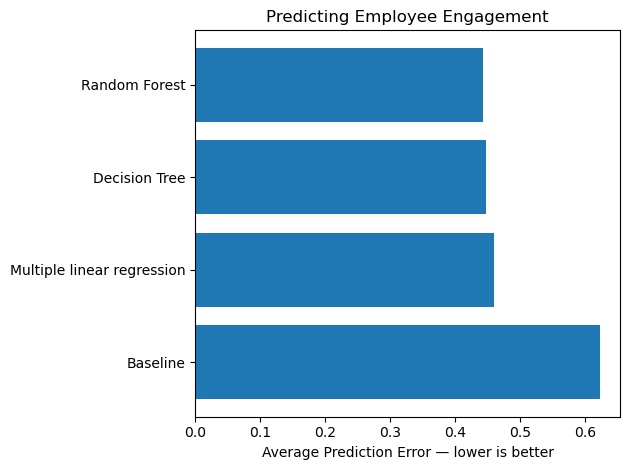

In [49]:
import matplotlib.pyplot as plt

plt.barh(
    ["Baseline", "Multiple linear regression", "Decision Tree", "Random Forest"],
    [baseline_error, error, tree_error, forest_error]
)

plt.xlabel("Average Prediction Error — lower is better")
plt.title("Predicting Employee Engagement")
plt.tight_layout()
plt.show()

Baseline: Predicts the same average engagement score for everyone.
Multiple linear regression: Uses a formula combining the four workplace ratings to predict engagement.
Decision Tree: Uses branching rules based on workplace ratings to predict engagement.
Random Forest: Combines many decision trees to predict engagement.
Lower error means more accurate predictions on the testing data.

In [50]:
import sqlite3

connection = sqlite3.connect("employee_engagement.db")

analysis_data.to_sql("employees", connection, index=False, if_exists="replace")

print("Employee data saved to SQLite")

Employee data saved to SQLite


In [51]:
query = """
SELECT Q57 AS leadership_rating,
       COUNT(*) AS employee_count,
       AVG(engagement_score) AS average_engagement
FROM employees
GROUP BY Q57
ORDER BY Q57
"""

pd.read_sql_query(query, connection)

,leadership_rating,employee_count,average_engagement
0,1.0,7645,3.061112
1,2.0,10758,3.534430
2,3.0,18241,3.779464
3,4.0,27204,4.145104
4,5.0,14837,4.689385


In [52]:
query = """
SELECT Q1 AS development_rating,
       COUNT(*) AS employee_count,
       AVG(engagement_score) AS average_engagement
FROM employees
GROUP BY Q1
ORDER BY Q1
"""

pd.read_sql_query(query, connection)

,development_rating,employee_count,average_engagement
0,1.0,2329,2.711035
1,2.0,5990,3.193957
2,3.0,9774,3.483344
3,4.0,36146,3.928794
4,5.0,24446,4.548981


In [53]:
dashboard_data = analysis_data[["engagement_score", "Q1", "Q5", "Q50", "Q57"]]

dashboard_data.to_csv("engagement_dashboard.csv", index=False)

print("Tableau file saved")

Tableau file saved


In [54]:
dashboard_data = analysis_data[["engagement_score", "Q1", "Q5", "Q50", "Q57"]]

dashboard_data.to_csv("/Users/prashastitripathi/Downloads/engagement_dashboard.csv", index=False)

print("Saved to Downloads")

Saved to Downloads


#export the Python correlation results for Tableau

In [55]:
correlation_results = analysis_data[["engagement_score", "Q1", "Q5", "Q50", "Q57"]].corr()

correlation_results["engagement_score"].drop("engagement_score").to_csv(
    "/Users/prashastitripathi/Downloads/engagement_correlations.csv",
    header=["correlation"]
)

print("Correlation results saved")

Correlation results saved


In [56]:
tableau_correlations = pd.DataFrame()

tableau_correlations["workplace_factor"] = [
    "Development opportunities",
    "Reasonable workload",
    "Supervisor listening",
    "Leadership motivation"
]

tableau_correlations["correlation"] = [
    correlations.loc["Q1", "engagement_score"],
    correlations.loc["Q5", "engagement_score"],
    correlations.loc["Q50", "engagement_score"],
    correlations.loc["Q57", "engagement_score"]
]

tableau_correlations.to_csv(
    "/Users/prashastitripathi/Downloads/engagement_correlations.csv",
    index=False
)

print(tableau_correlations)

            workplace_factor  correlation
0  Development opportunities     0.577027
1        Reasonable workload     0.362752
2       Supervisor listening     0.457333
3      Leadership motivation     0.573349
